In [138]:

from gal_evol.create_cutouts import Cutouts
from gal_evol.create_segments import Segmentation
from gal_evol.catalog_match import Match_Gal
from gal_evol.background import Background_remove
from gal_evol.image_process import Center_Cutouts, Save_Data
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from astropy.io import fits
from astropy import units as u
from astropy.coordinates import SkyCoord

In [139]:
data_path = '/media/himanshu/MyHDD/data_galaxy_evolution/data/'  # path to HST-JWST fits images
# loading EELGS and control galaxy samples
catalog = data_path + 'sample_details/'
eelgs = catalog + 'eelgs_28aug2024.dat'
control = catalog + 'control_28aug2024.dat'

In [140]:

c0 = fits.open(data_path+'/catalog/hlsp_jades_jwst_nircam_goods-s-deep_photometry_v2.0_catalog.fits')
c1 = fits.open(data_path+'/catalog/hlsp_jades_jwst_nirspec_goods-s-deephst_clear-prism_line-fluxes_v1.0_catalog.fits')
c2 = fits.open(data_path+'/catalog/hlsp_jades_jwst_nirspec_goods-s-deephst_gratings_line-fluxes_v1.0_catalog.fits')
c3 = fits.open(data_path+'/catalog/hlsp_jades_jwst_nirspec_goods-s_gratings-line-fluxes_v1.1_catalog.fits')
c4 = fits.open(data_path+'/catalog/hlsp_jades_jwst_nirspec_goods-s_prism-line-fluxes_v1.1_catalog.fits')


In [561]:

# extracting sample data : id, ra, dec, photo_z, spec_z
use_control = False
if use_control == True:
    data_columns = np.loadtxt(control, dtype='str', delimiter=',')[0]
    sample_data  = np.loadtxt(control, delimiter=',', skiprows=1)
else:
    
    data_columns = np.loadtxt(eelgs, dtype='str', delimiter=',')[0]
    sample_data  = np.loadtxt(eelgs, delimiter=',', skiprows=1)
    
new_dtype = [(name, float) for name in data_columns]
sample_data = np.array([tuple(row) for row in sample_data], dtype=new_dtype)


tol = 0.0003
if use_control == True:
    cat_indx_match = np.load('../data/cat_matching_index_tol_control_%s.npy'%tol, allow_pickle=True)
else:
    cat_indx_match = np.load('../data/cat_matching_index_tol_eelgs_%s.npy'%tol, allow_pickle=True)


In [562]:
# data selection for high redshift
ind = np.where(sample_data['zspec'] > 3.08)
sample_data = sample_data[ind]
#if use_control == True:
#    ra, dec, zspec = sample_data['RA'][ind], sample_data['dec'][ind], sample_data['zspec'][ind]
#else:
#    ra, dec, zspec = sample_data['RA'.lower()][ind], sample_data['dec'][ind], sample_data['zspec'][ind]
#    

In [563]:
sample_data.shape

(27,)

In [564]:
# loading fits files for two filters, e.g. first non-ionizing filter (base filter), second ionizing filter

def load_fits(filt0, filt1):
    '''
    filt0: name of the filter
    
    filt1: name of the filter
    
    returns: fits filters and weights
    '''
    fitsfile1     = data_path  + 'Jades-Filters/hlsp_jades_jwst_nircam_goods-s-deep_%s_v2.0_drz.fits'%filt1
    fitsfile0     = data_path  + 'Jades-Filters/hlsp_jades_jwst_nircam_goods-s-deep_%s_v2.0_drz.fits'%filt0
    #hlsp_fresco_hst_wfc3-ir_goods-s_f110w_v1.0_sci
    
    return fitsfile0, fitsfile1

In [565]:
ls /media/himanshu/MyHDD/data_galaxy_evolution/data/Jades-Filters/

hlsp_jades_jwst_nircam_goods-s-deep_f090w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f150w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f182m_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f200w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f210m_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f277w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f335m_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f356w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f410m_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f430m_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f444w_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f460m_v2.0_drz.fits*
hlsp_jades_jwst_nircam_goods-s-deep_f480m_v2.0_drz.fits*


In [566]:
filt0='f444w' # non-ionizing filter
filt1='f444w' # ionizing filter
fitsfile0, fitsfile1 = load_fits(filt0=filt0, filt1=filt1)
#loading the filters
f0  = fits.open(fitsfile0)
f1  = fits.open(fitsfile1)

flux_units = f0[0].header['bunit']
# Check if FILTER2 or FILTER is present in the header
if 'FILTER2' in f0[0].header or 'FILTER' in f0[0].header:
    # Access the filters, defaulting to empty string if not present
    filter2 = f0[0].header.get('FILTER2', '')
    filter1 = f0[0].header.get('FILTER', '')

    # Determine the filter that starts with 'F'
    filt = filter2 if filter2.startswith('F') else (filter1 if filter1.startswith('F') else None)
    
    if filt:
        print(f"Selected Filter: {filt}")
    else:
        print("No filter starts with 'F'.")
else:
    print("Neither FILTER2 nor FILTER is present in the header.")


Selected Filter: F444W


In [567]:
help(Cutouts)

Help on class Cutouts in module gal_evol.create_cutouts:

class Cutouts(builtins.object)
 |  Cutouts(header_index, size_arsec, tolerance_arcsec)
 |
 |  A class for creating and processing cutout images from astronomical data.
 |
 |  Methods:
 |  - __init__(header_index, size_arcsec, tolarance_arcsec):
 |      Initializes the Cutouts class with header index, cutout size, and tolerance.
 |
 |  - create_cutouts(image, sky_position):
 |      Generates a cutout image centered on the peak flux near a specified sky position.
 |
 |  - process_cutout_array(sky_position_arr, target_filter_image, secondary_filter_image, avoid_target=False):
 |      Processes an array of sky positions to generate cutouts for target and secondary filter images.
 |
 |  Methods defined here:
 |
 |  __init__(self, header_index, size_arsec, tolerance_arcsec)
 |      Parameters:
 |      - header_index (int): header data index,
 |      - size_arcsec (float): crop image size.
 |      - tolerance_arcsec (float): Angular si

In [568]:
if use_control==True:
    sky_position_arr = np.array([sample_data['RA'], sample_data['dec']]).T
else:
    sky_position_arr = np.array([sample_data['ra'], sample_data['dec']]).T


In [569]:
cutouts = Cutouts(size_arsec=5, header_index=1, tolerance_arcsec=0.1)
cutout_target_image_arr, cutout_secondary_image_arr, err_arr = cutouts.process_cutout_array(sky_position_arr=sky_position_arr, 
                                                                target_filter_image=f0, secondary_filter_image=f1, \
                                                                avoid_target=False)

Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 

Peak position in cutout: (82, 80)
Peak position in cutout: (81, 81)
Peak position in cutout: (80, 84)
Peak position in cutout: (80, 84)
Peak position in cutout: (80, 84)
Peak position in cutout: (80, 82)
Peak position in cutout: (80, 82)
Peak position in cutout: (83, 82)
Peak position in cutout: (81, 81)
Peak position in cutout: (86, 82)
Peak position in cutout: (80, 82)
Peak position in cutout: (83, 81)
Peak position in cutout: (82, 80)
Peak position in cutout: (82, 80)
Peak position in cutout: (80, 82)
Peak position in cutout: (80, 82)
Peak position in cutout: (80, 82)
Peak position in cutout: (81, 83)
Peak position in cutout: (81, 81)
Peak position in cutout: (81, 85)
Peak position in cutout: (80, 82)
Peak position in cutout: (81, 81)
Peak position in cutout: (80, 82)
Peak position in cutout: (82, 82)
Peak position in cutout: (83, 81)
Peak position in cutout: (84, 80)
Peak position in cutout: (80, 83)


Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 1236397528.843 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    23.044721 from OBSGEO-[XYZ].
Set OBSGEO-H to 

In [570]:
len(cutout_target_image_arr), err_arr

(27, array([], dtype=float64))

0


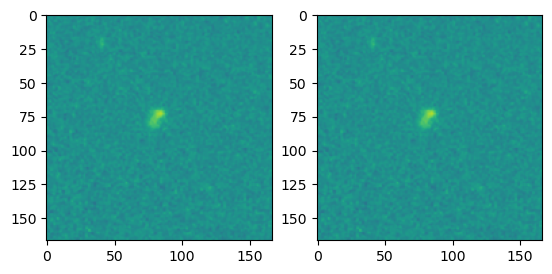

1


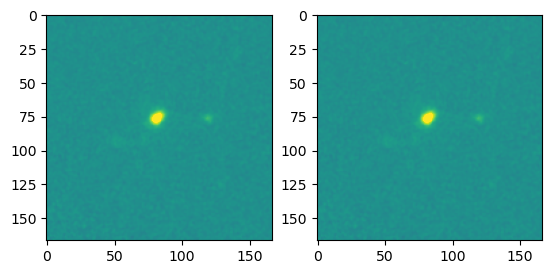

2


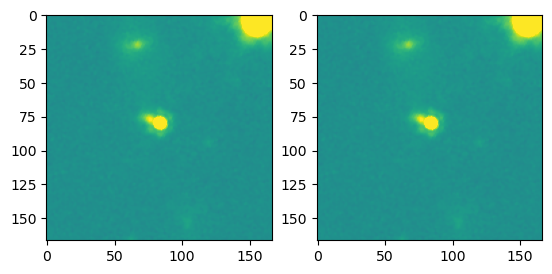

3


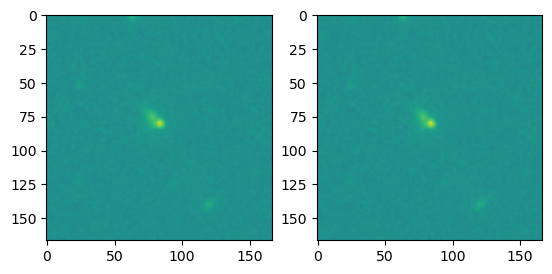

4


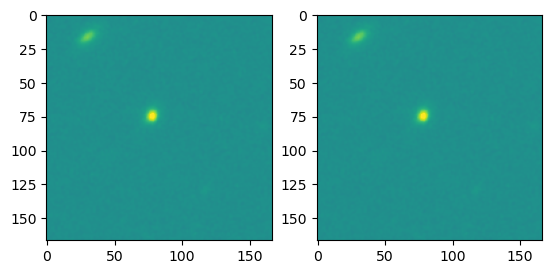

5


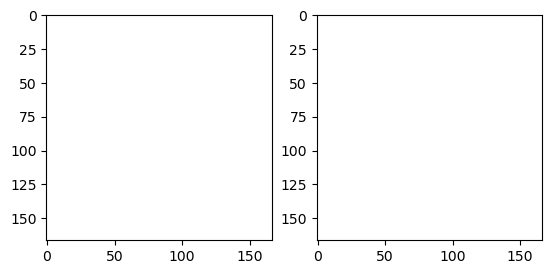

6


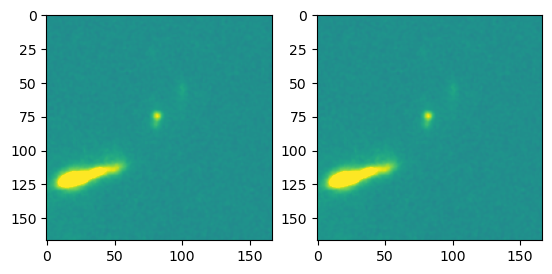

7


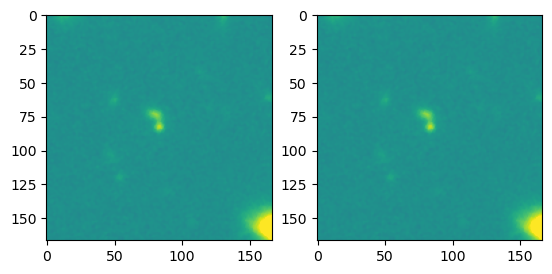

8


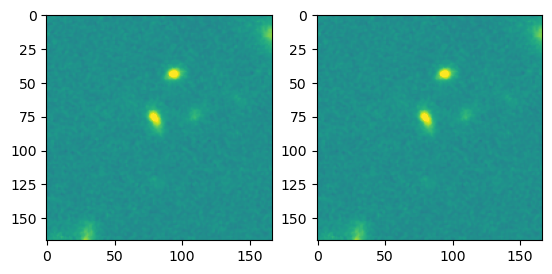

9


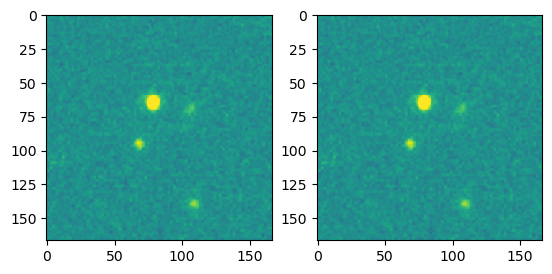

10


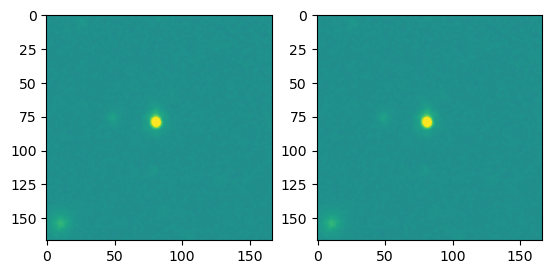

11


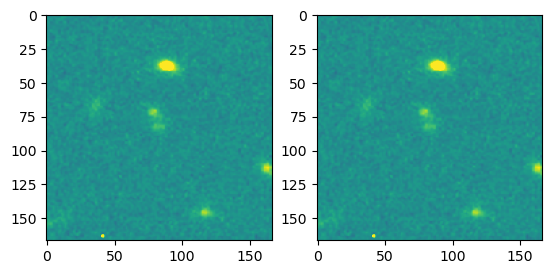

12


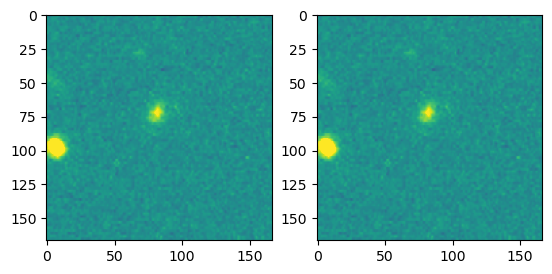

13


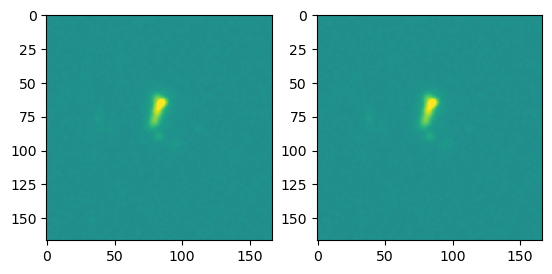

14


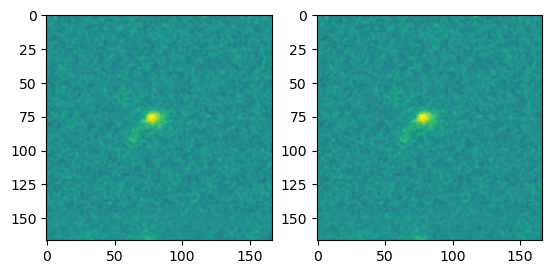

15


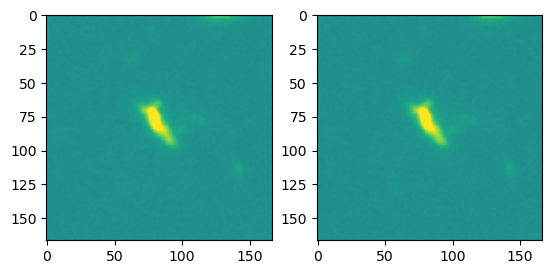

16


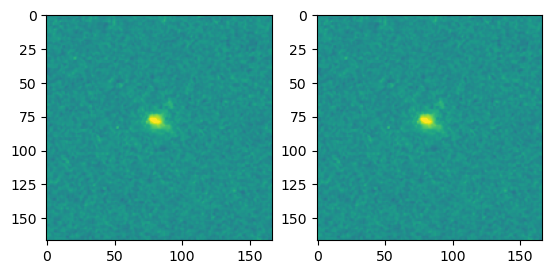

17


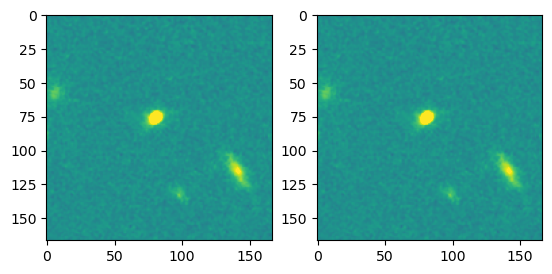

18


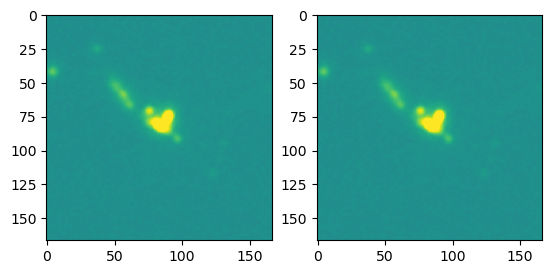

19


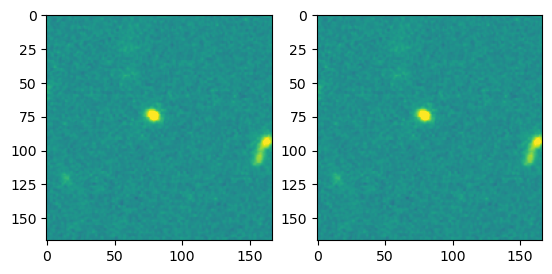

20


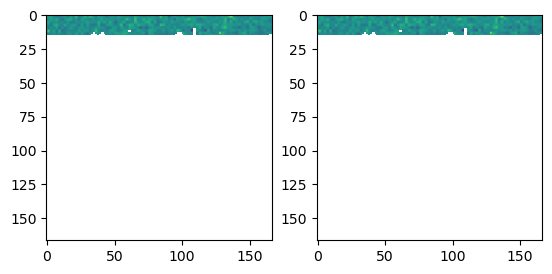

21


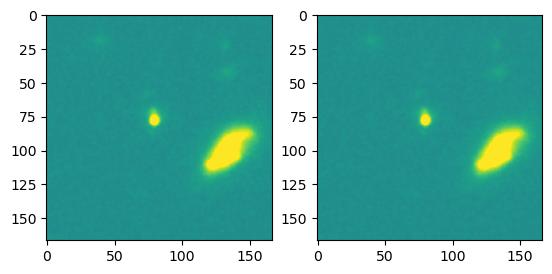

22


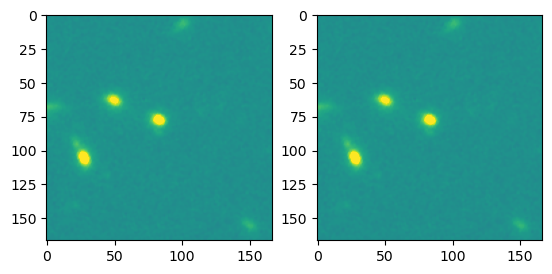

23


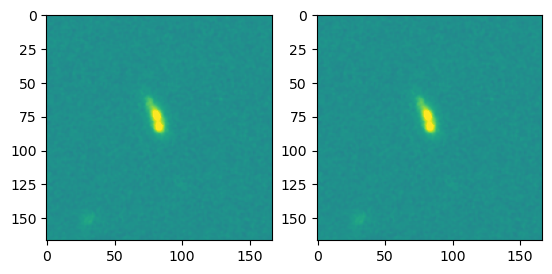

24


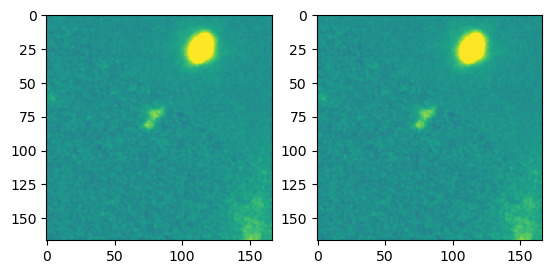

25


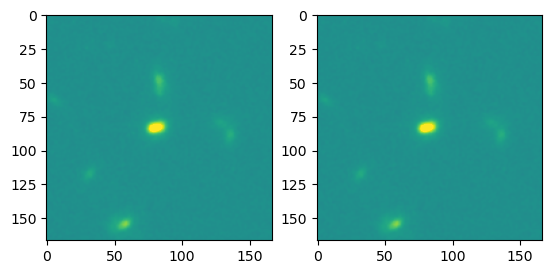

26


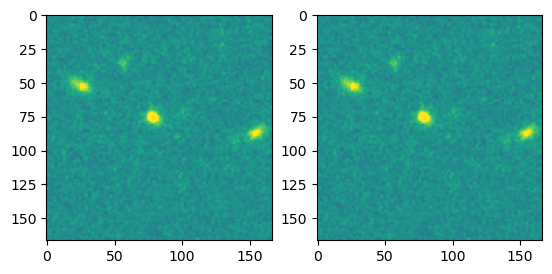

In [571]:
for i in range(len(cutout_target_image_arr)):
    print(i)
    plt.subplot(121)
    plt.imshow(np.ma.masked_equal(cutout_target_image_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1)
    
    plt.subplot(122)
    plt.imshow(np.ma.masked_equal(cutout_secondary_image_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1)

    plt.show()

In [572]:
good_ind  = np.arange(len(sample_data))
#if err_arr.size !=0:
#    good_ind  = np.delete(good_ind, err_arr)

In [573]:
box_size=8
filt_size=7
npixels_segmentation=20
npixels_deblend=20
nlevels=20
contrast=0.001
sigma_clip=3
create_segmentation = Segmentation(use_median_background=True, box_size=box_size, nlevels=nlevels, filt_size=filt_size,\
                                    npixels_segmentation=npixels_segmentation, npixels_deblend=npixels_deblend,\
                                        contrast=contrast, sigma_clip=sigma_clip)
segm_deblend_arr, \
    segment_arr, target_data_bg_sub_arr, \
        target_data_bg_sub_arr_convolved, err_ind_arr = create_segmentation.get_segmentations_arr(image_arr=cutout_target_image_arr)
        
_, _, secondary_data_bg_sub_arr, \
        secondary_data_bg_sub_arr_convolved, _ = create_segmentation.get_segmentations_arr(image_arr=cutout_secondary_image_arr)

No sources detected. Skipping this cutout.
No sources detected. Skipping this cutout.


In [574]:
#for i in range(len(cutout_target_image_arr)):
#    
#    coord = SkyCoord(ra=sample_data['RA'][i] * u.deg, dec=sample_data['dec'][i] * u.deg, frame='icrs')
#    
#    # Convert the sky coordinates to pixel coordinates using the WCS of the image
#    sky_pix_x, sky_pix_y = cutout_target_image_arr[i].wcs.world_to_pixel(coord)
#    print(i)
#    plt.subplot(141)
#    plt.imshow(np.ma.masked_equal(target_data_bg_sub_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, )
#    plt.scatter(sky_pix_x, sky_pix_y, color='red', marker='x', )#label='Coord')
#    
#    plt.subplot(142)
#    plt.title('%s'%sample_data['id'][i])
#    plt.imshow(np.ma.masked_equal(secondary_data_bg_sub_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1)
#
#    plt.subplot(143)
#    plt.imshow(segm_deblend_arr[i], )
#
#    plt.subplot(144)
#    plt.imshow(segment_arr[i], )
#
#    plt.show()# 7071.,8923., 10400., 10462., 11172., 12824., 12898., 12935., 17810., 19289., 19310., 19796.

In [575]:
plt.imshow((segment_arr[55].data==5)+ (segment_arr[55].data==6))

IndexError: list index out of range

In [577]:
force_segment_indicies = [55]
force_segment_labels = [5, 6]

In [578]:
if use_control == False:
    bad_deblended_objectIDs = np.array([22136., 16603., 19437.]) # using normal segments at these objects
else:
    bad_deblended_objectIDs = np.array([7071.,8923., 10462., 11172., 12824., 12898., 12935., 15852., 17810., 22590., 22654.,])#[12898.,13406.,14122., 17810., 21067.])#8166., 8923., 10400., 10462., 11172., 12824., 12935., 14122., 15852., 17810., 19310., 22590., 22654.]) # using normal segments at these objects


In [579]:
good_ind.shape, len(cat_indx_match), sample_data.shape, len(cutout_target_image_arr), len(segment_arr), len(segm_deblend_arr)

((27,), 27, (27,), 27, 27, 27)

In [580]:
#cat_indx_match = np.delete(cat_indx_match, err_arr)
#sample_data = np.delete(sample_data, err_arr)

In [581]:
class Match_Gal():
    """
    Match_Gal
    A class for processing and analyzing galaxy segmentation maps, particularly focusing on 
    high-redshift galaxies. This class provides methods to combine segments of high-redshift 
    galaxies into a single mask and identify background segments not included in the high-redshift mask.
    Methods:
    --------
    - combine_highz_segments(segment, wcs, galaxy_ra, galaxy_dec, galaxy_redshifts, z_lim=3.08):
        background segments not included in the high-redshift mask. Processes a segmentation 
        map to identify and combine regions corresponding to galaxies with redshifts greater 
        than a specified limit.
    - combine_highz_segments_arr(good_indices, objectID_arr, bad_deblended_objectIDs, catalog, 
      catalog_matcher, wcs_arr, segments_arr, deblended_segments_arr, 
      use_3sigma_redshift_confidence=True, z_lim=3.08):
        Processes multiple segmentation maps and catalogs to generate masks for high-redshift 
        galaxies and background segments. Handles arrays of segmentation maps and associated 
        metadata, allowing for batch processing of galaxy data.
    """
    
    def __init__(self):
        pass
        
    def combine_highz_segments(self, segment, wcs, galaxy_ra, galaxy_dec, galaxy_redshifts, z_lim=3.08, do_force_segment=False, force_segmentation_values=[]):
        """
        Combines segments of high-redshift galaxies into a single mask and identifies 
        background segments not included in the high-redshift mask.

        This method processes a segmentation map to identify and combine regions 
        corresponding to galaxies with redshifts greater than a specified limit. 
        It also creates a mask for all other segments not included in the high-redshift mask.

        Parameters:
        -----------
        segment : Segment
            A segmentation map where each pixel is labeled with an integer corresponding 
            to a specific segment.
        wcs : WCS
            World Coordinate System (WCS) object for converting between world and pixel coordinates.
        galaxy_ra : array-like
            Right Ascension (RA) values of galaxies in degrees.
        galaxy_dec : array-like
            Declination (Dec) values of galaxies in degrees.
        galaxy_redshifts : array-like
            Redshift values of galaxies.
        z_lim : float, optional
            Redshift threshold above which galaxies are considered high-redshift. Defaults to 3.08.
        do_force_segment : bool, optional
            If True, forces specific segments to be included in the high-redshift mask. Defaults to False.
        force_segmentation_values : list, optional
            List of segment labels to forcefully include in the high-redshift mask. Defaults to an empty list.

        Returns:
        --------
        tuple
            - combined_segments (ndarray): A boolean mask where regions corresponding 
              to high-redshift galaxies are marked as True.
            - bg_segments_mask (ndarray): A boolean mask where regions corresponding 
              to background segments (not part of high-redshift galaxies) are marked as True.
        """
        # Convert galaxy RA/Dec to pixel coordinates using WCS
        galaxies_coords = SkyCoord(ra=galaxy_ra, dec=galaxy_dec, unit="deg")
        galaxy_pixels = wcs.world_to_pixel(galaxies_coords)
        galaxy_x, galaxy_y = galaxy_pixels[0], galaxy_pixels[1]
        # Identify galaxies with redshift > z_lim
        high_z_indices = np.where(galaxy_redshifts > z_lim)[0]
        high_z_x = galaxy_x[high_z_indices]
        high_z_y = galaxy_y[high_z_indices]
        # Initialise a combined mask for high-z galaxies
        combined_segments = np.zeros_like(segment.data, dtype=bool)
        # Loop through all high-redshift galaxies
        for x, y in zip(high_z_x, high_z_y):
            # Convert pixel coordinates to integer
            x = int(round(x))
            y = int(round(y))
            # Ensure the coordinates are within image bounds
            if 0 <= x < combined_segments.shape[1] and 0 <= y < combined_segments.shape[0]:
                # Find the segment label corresponding to this pixel
                label = segment.data[y, x]
                if label > 0:  # Exclude background (label 0)
                    # Add the current segment to the combined high-z mask
                    combined_segments |= (segment.data == label)
        if do_force_segment == True:
            for i in range(len(force_segmentation_values)):
                combined_segments |= (segment.data == force_segmentation_values[i])
        # Create the masked image by setting high-z galaxy regions to NaN
        #combined_segments_data = np.where(combined_segments, np.nan, data.data)
        # Create a mask for all other segments not included in the high-z mask
        bg_segments_mask = (segment.data > 0) & ~combined_segments
        return combined_segments, bg_segments_mask

    def combine_highz_segments_arr(self, good_indices, objectID_arr,
                                   bad_deblended_objectIDs, catalog, catalog_matcher,
                                   wcs_arr, segments_arr, deblended_segments_arr,
                                   use_3sigma_redshift_confidence=True, force_segmentation_indices=[],
                                   force_segmentation_values=[], z_lim=3.08):
        """
        Combines high-redshift galaxy segmentation masks for a set of objects.
        This method processes a list of objects, extracting their photometric redshifts, 
        coordinates, and segmentation masks to generate combined segmentation masks 
        for high-redshift galaxies. It also handles cases where objects are flagged 
        as poorly deblended.
            good_indices (list): Indices of objects to process.
            objectID_arr (list): Array of object IDs corresponding to the input objects.
            bad_deblended_objectIDs (list): List of object IDs flagged as poorly deblended.
            catalog (list): Catalog data containing photometric and positional information.
            catalog_matcher (list): Mapping between input indices and catalog entries.
            wcs_arr (list): Array of WCS (World Coordinate System) objects for each object.
            segments_arr (list): Array of segmentation masks for the objects.
            deblended_segments_arr (list): Array of deblended segmentation masks for the objects.
            use_3sigma_redshift_confidence (bool, optional): If True, uses the lower-limit 
                (99 percent confidence interval) photometric redshift. Defaults to True.
            z_lim (float, optional): Redshift limit to classify high-redshift galaxies. 
                Defaults to 3.08.
            tuple: A tuple containing:
                - combined_segment_mask_arr (list): List of combined segmentation masks 
                  for high-redshift galaxies.
                - bg_segments_mask_arr (list): List of background segmentation masks.
        """
        combined_segment_mask_arr, bg_segments_mask_arr = [], [] 
        for ind in good_indices:

            try:
                # Extract RA, Dec, and redshift for the source
                if use_3sigma_redshift_confidence:
                    print('using lower-limit (99 percent confidence interval) photometric redshift')
                    phot_zz   = catalog[-1].data[catalog_matcher[ind][0]]['EAZY_l99']
                else:
                    print('using mean photometric redshift')
                    phot_zz = catalog[-1].data[catalog_matcher[ind][0]]['EAZY_z_a']
                
                ra_s, dec_s = catalog[2].data[catalog_matcher[ind][0]]['ra'], catalog[2].data[catalog_matcher[ind][0]]['dec']
                # Select the appropriate segmentation mask
                if objectID_arr[ind] not in bad_deblended_objectIDs:
                    segment = deblended_segments_arr[ind]
                else:
                    segment = segments_arr[ind]
                # Generate masks for high-z galaxies
                if ind in force_segmentation_indices:
                    print('using forced segmentation', ind)
                    combined_segment_mask, bg_segments_mask = self.combine_highz_segments(
                        segment=segment,
                        wcs=wcs_arr[ind].wcs,
                        galaxy_ra=ra_s,  # Ensure RA is an array
                        galaxy_dec=dec_s,  # Ensure Dec is an array
                        galaxy_redshifts=phot_zz,  # Ensure redshifts are an array
                        z_lim=z_lim, 
                        do_force_segment=True,
                        force_segmentation_values=force_segmentation_values)
                    plt.imshow(combined_segment_mask)
                    combined_segment_mask_arr.append(combined_segment_mask)
                    bg_segments_mask_arr.append(bg_segments_mask)
                else:
                    combined_segment_mask, bg_segments_mask = self.combine_highz_segments(
                        segment=segment,
                        wcs=wcs_arr[ind].wcs,
                        galaxy_ra=ra_s,  # Ensure RA is an array
                        galaxy_dec=dec_s,  # Ensure Dec is an array
                        galaxy_redshifts=phot_zz,  # Ensure redshifts are an array
                        z_lim=z_lim, 
                        do_force_segment=False)
                    combined_segment_mask_arr.append(combined_segment_mask)
                    bg_segments_mask_arr.append(bg_segments_mask)

            except Exception as e:
                print(f"Error processing index: {e}")
                continue
        return combined_segment_mask_arr, bg_segments_mask_arr

In [582]:
len(combine_highz_segment_arr), len(bg_segment_arr),

(90, 90)

0


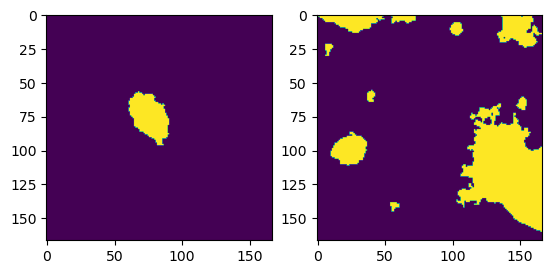

1


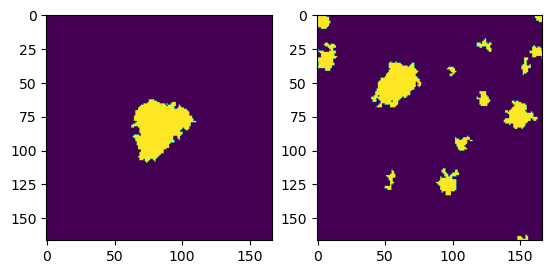

2


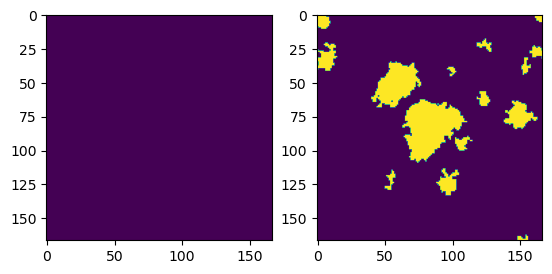

3


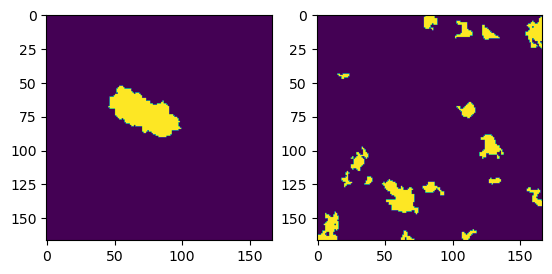

4


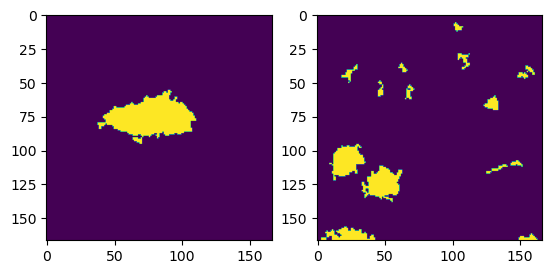

5


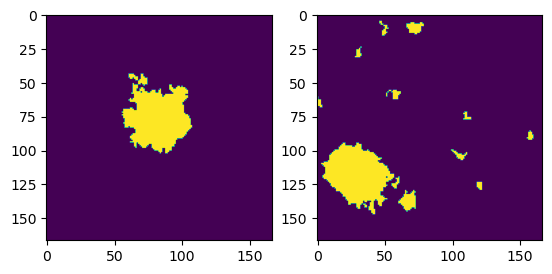

6


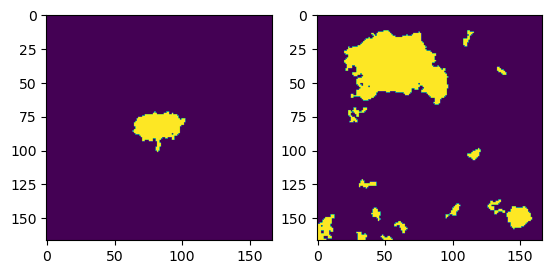

7


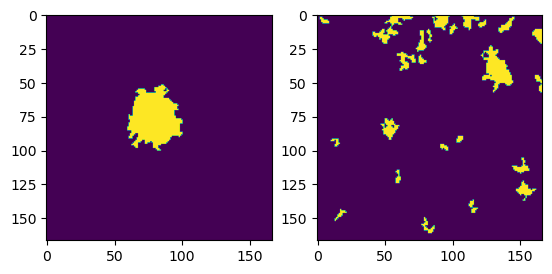

8


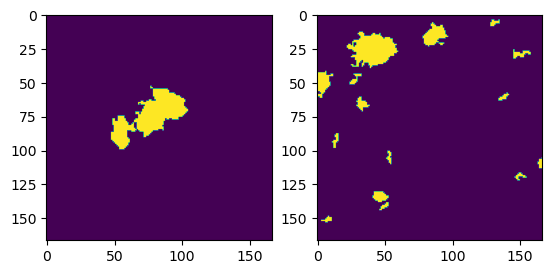

9


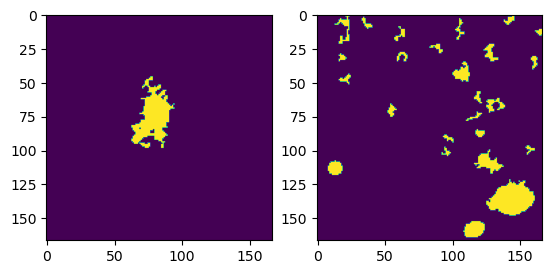

10


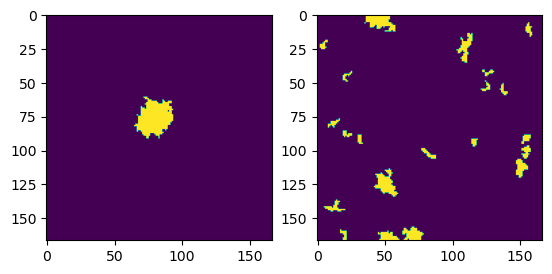

11


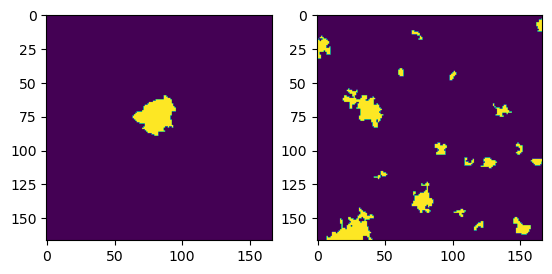

12


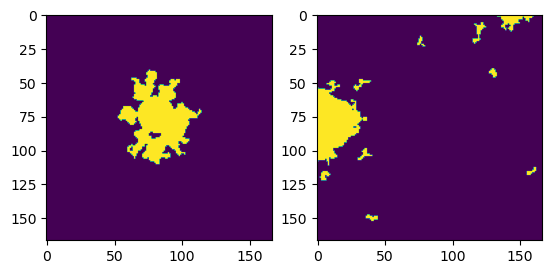

13


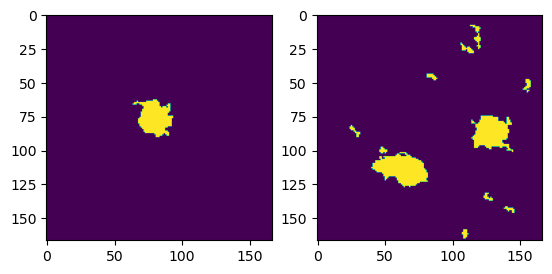

14


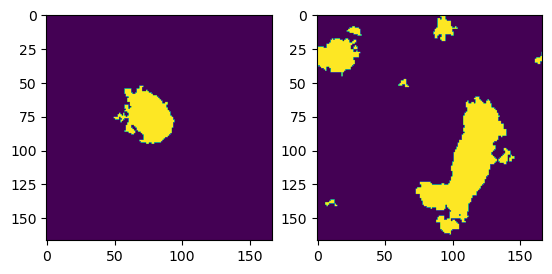

15


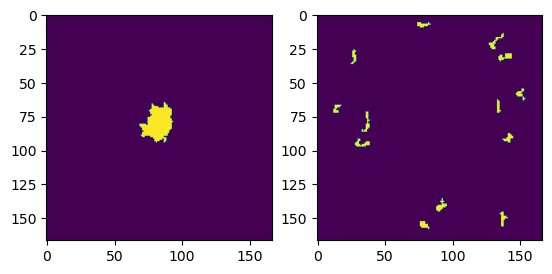

16


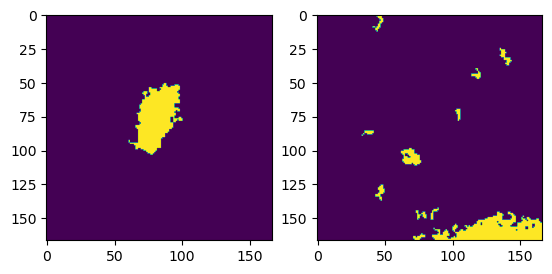

17


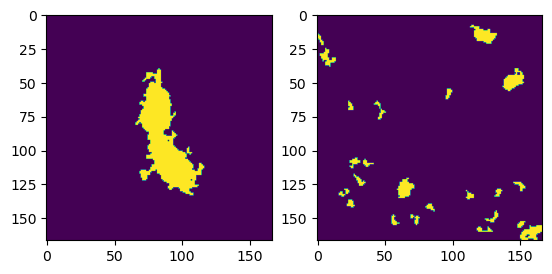

18


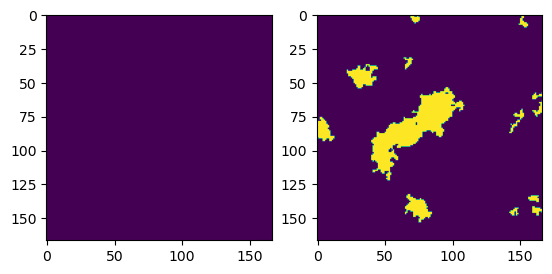

19


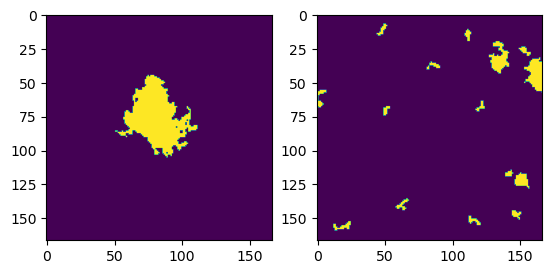

20


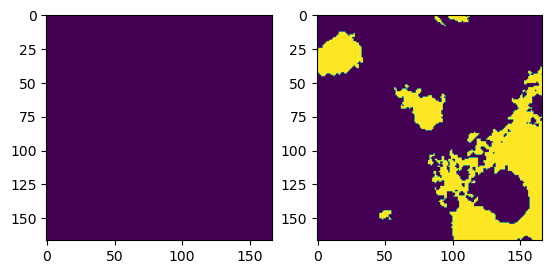

21


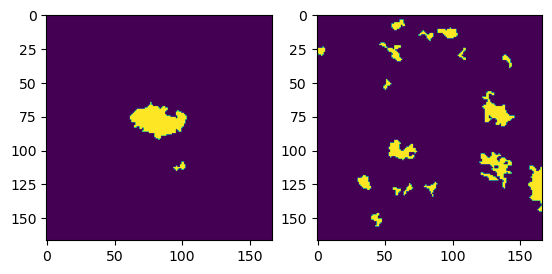

22


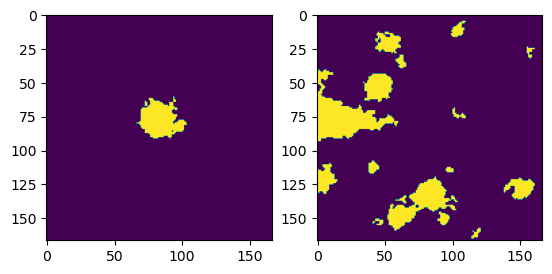

23


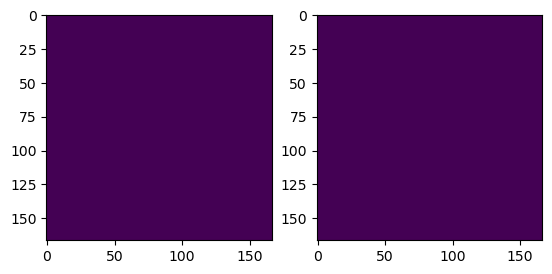

24


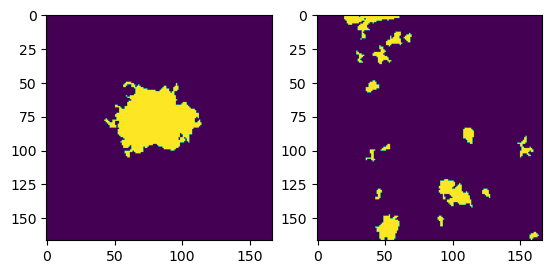

25


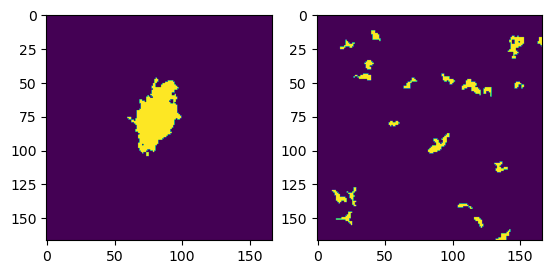

26


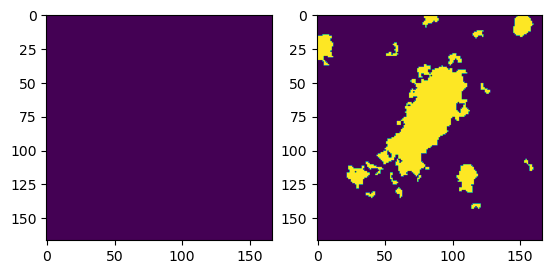

27


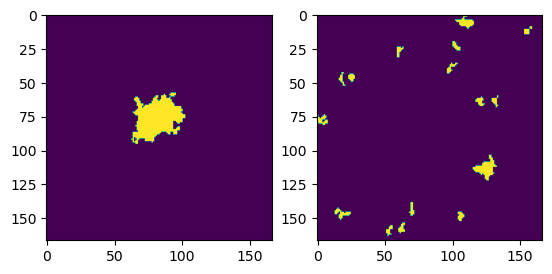

28


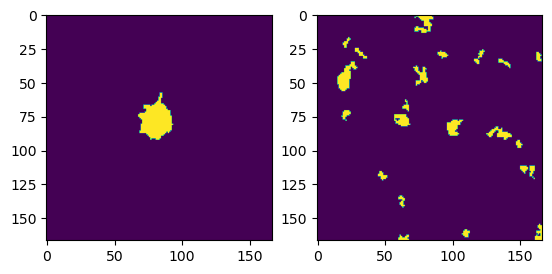

29


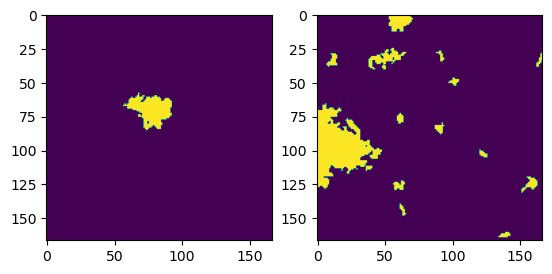

30


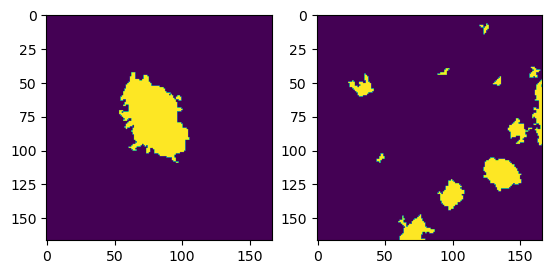

31


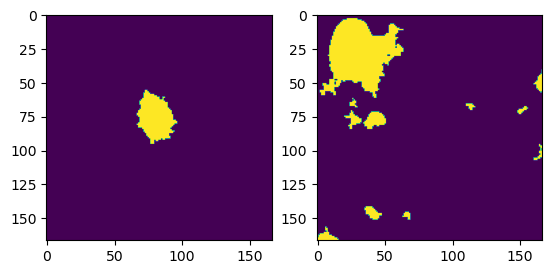

32


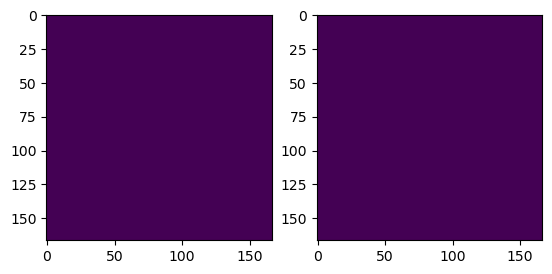

33


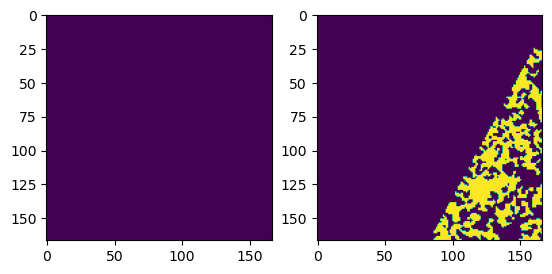

34


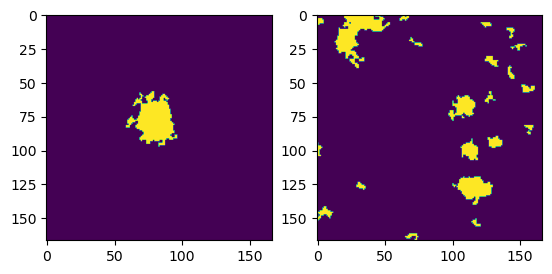

35


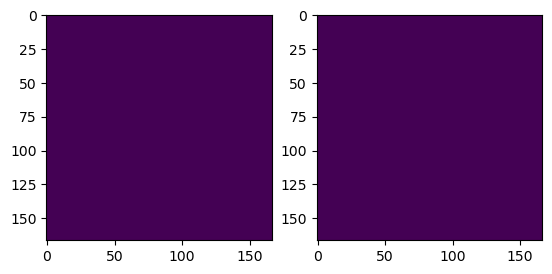

36


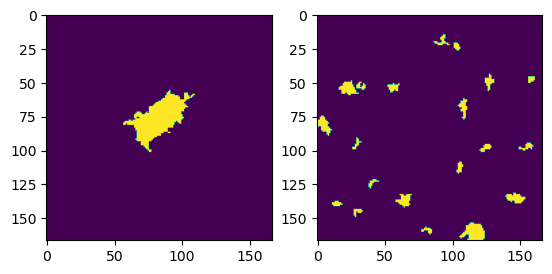

37


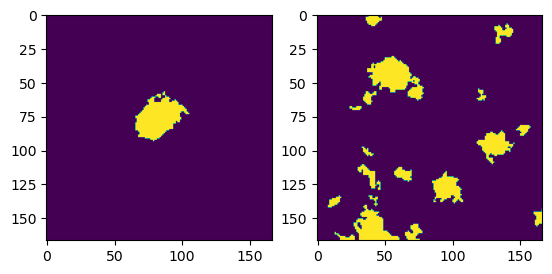

38


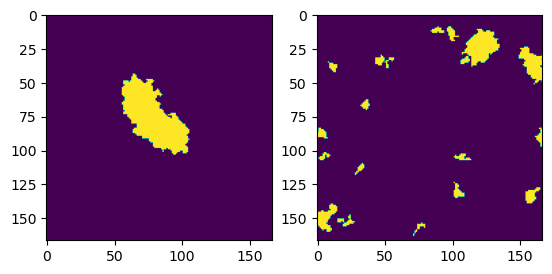

39


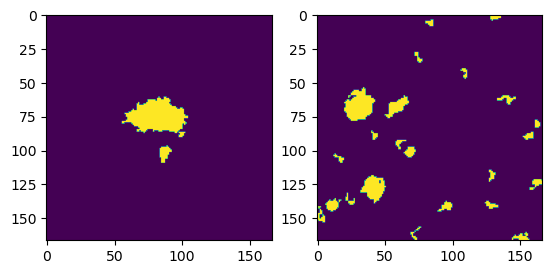

40


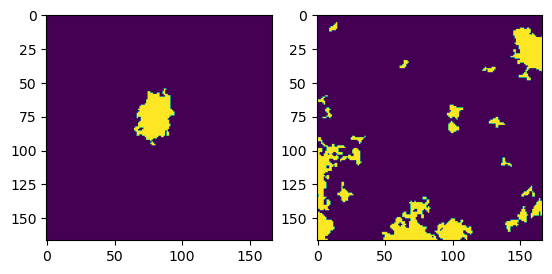

41


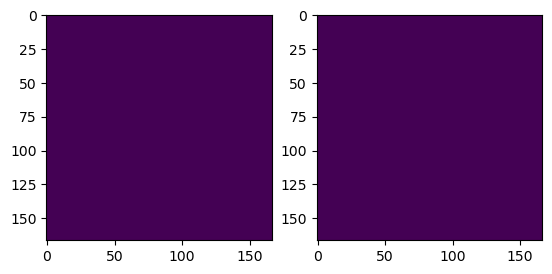

42


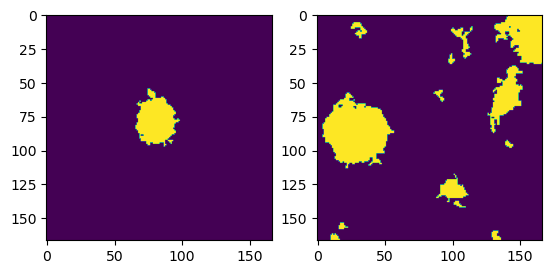

43


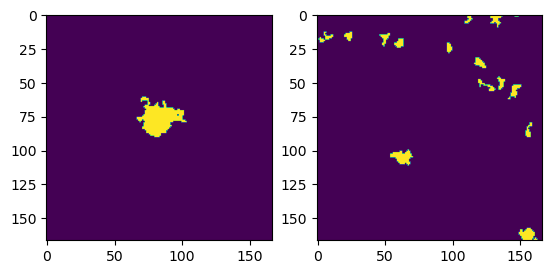

44


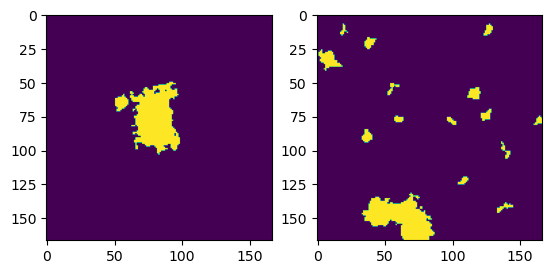

45


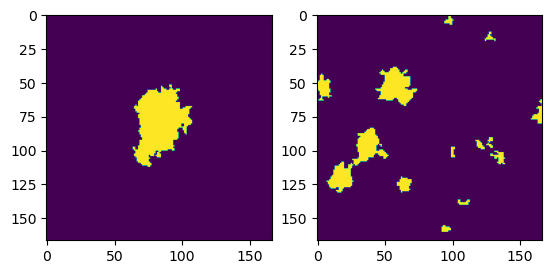

46


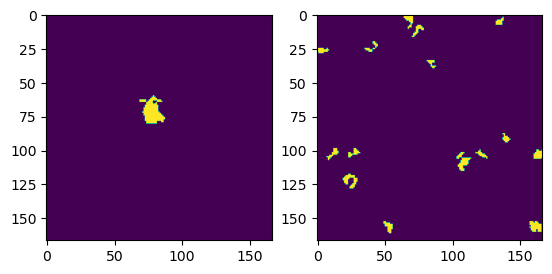

47


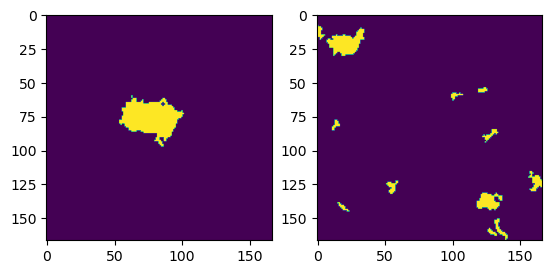

48


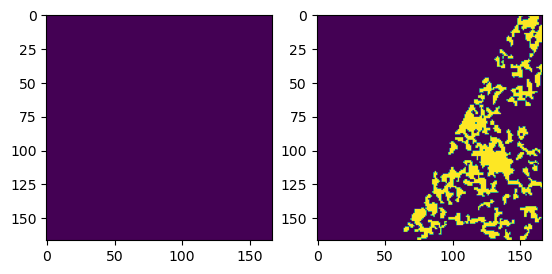

49


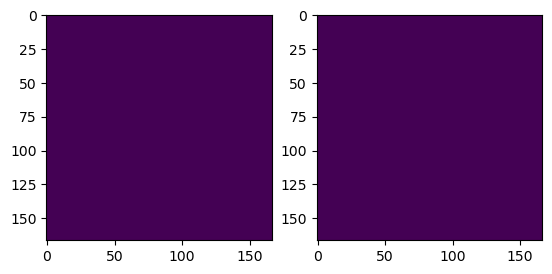

50


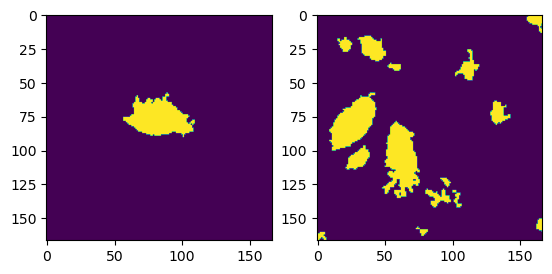

51


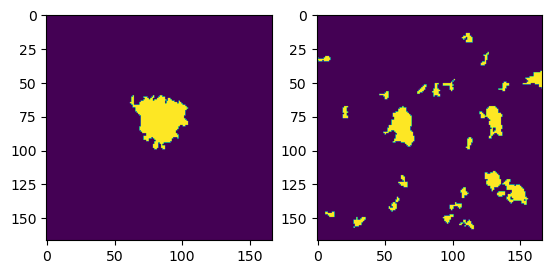

52


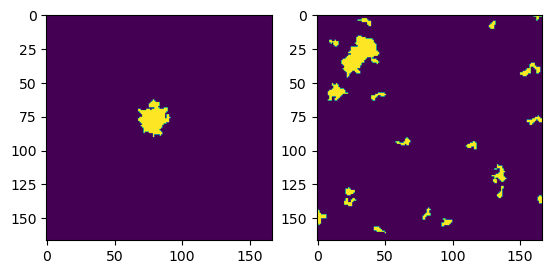

53


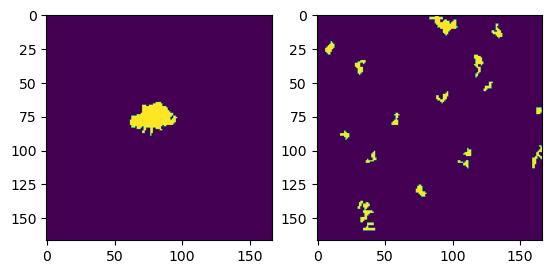

54


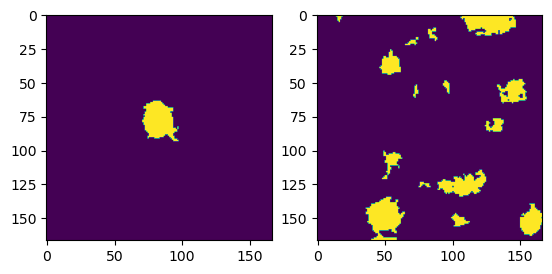

55


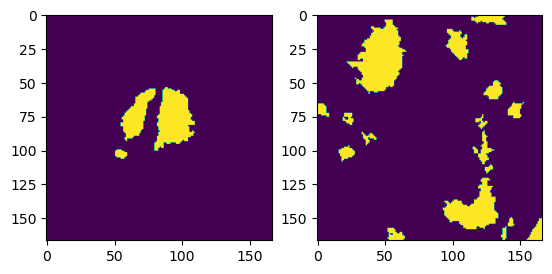

56


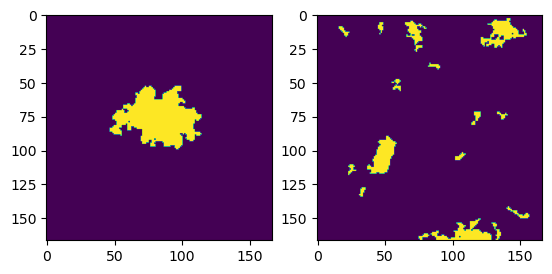

57


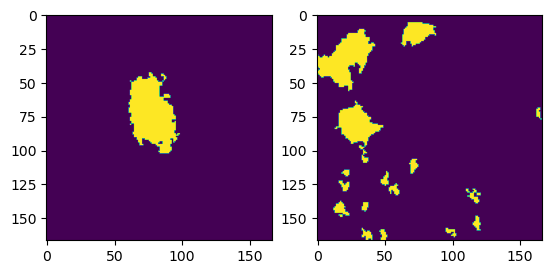

58


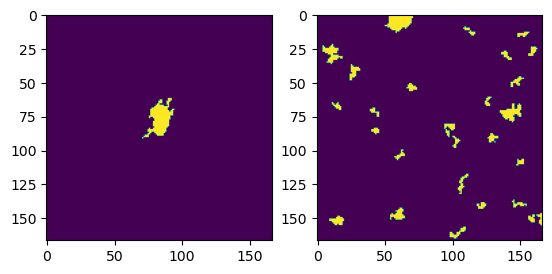

59


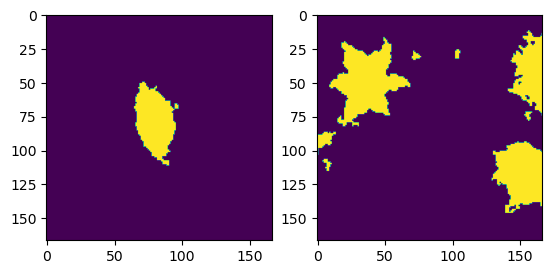

60


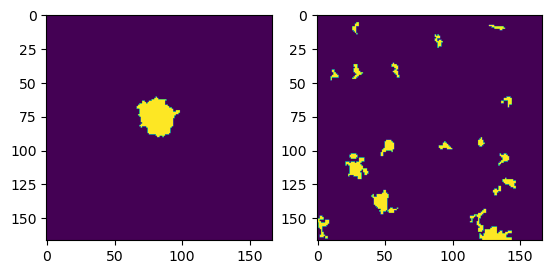

61


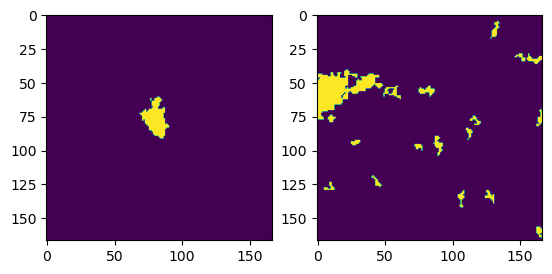

62


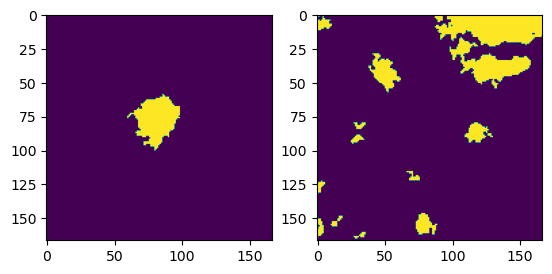

63


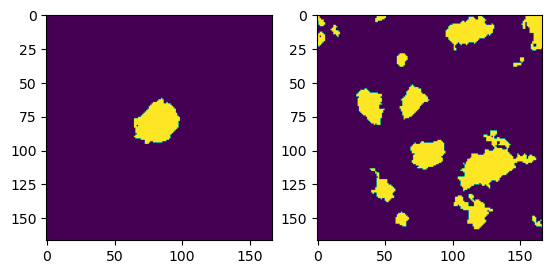

64


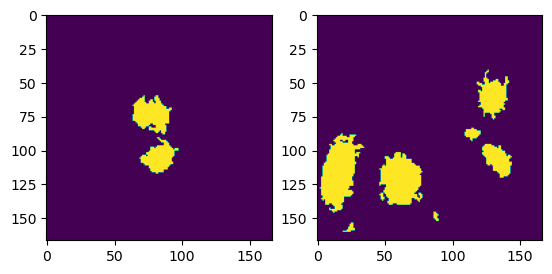

65


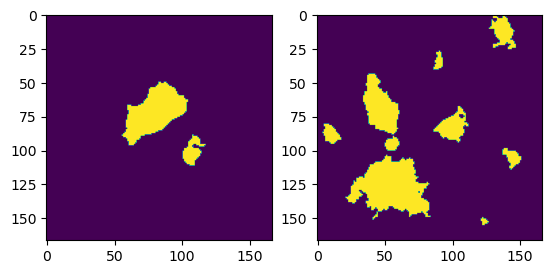

66


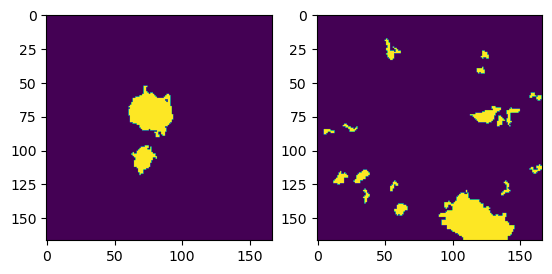

67


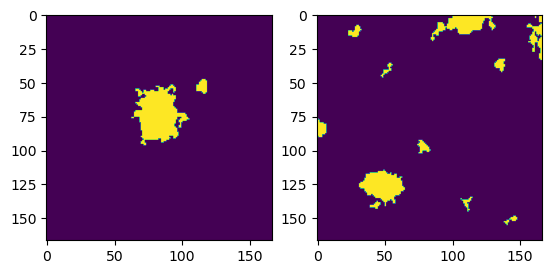

68


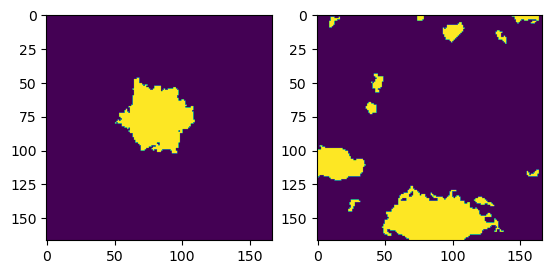

69


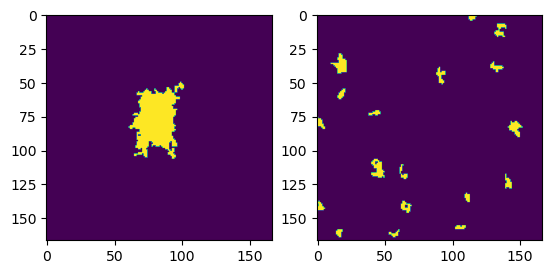

70


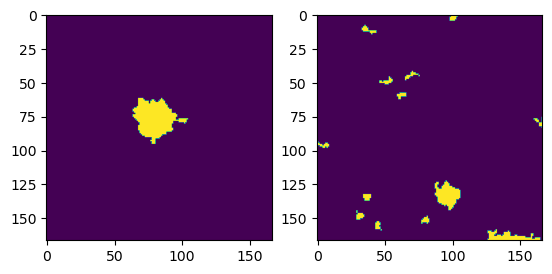

71


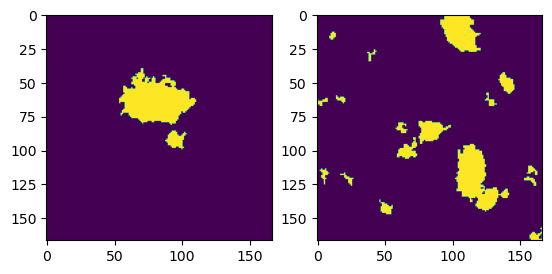

72


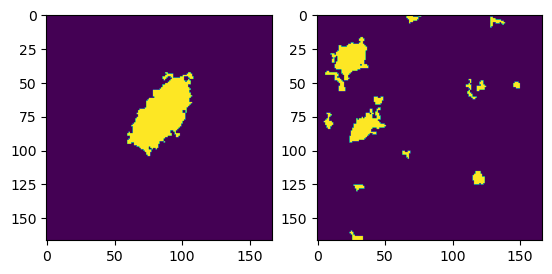

73


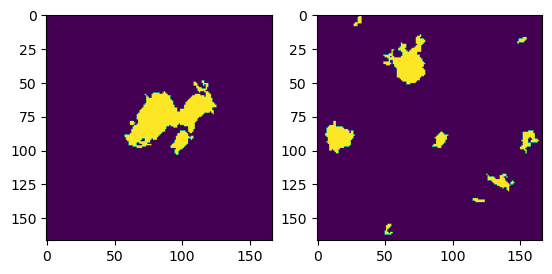

74


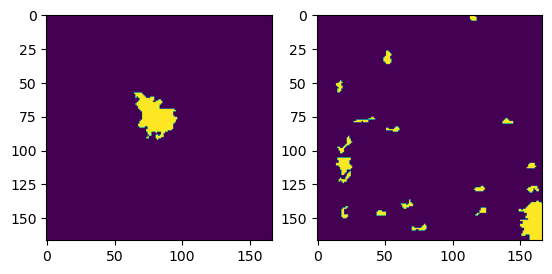

75


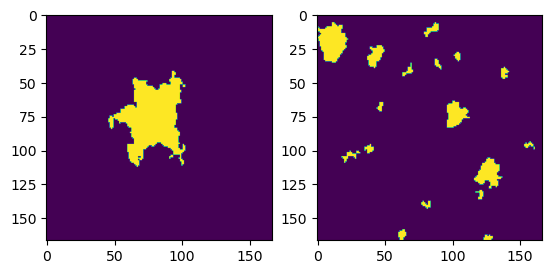

76


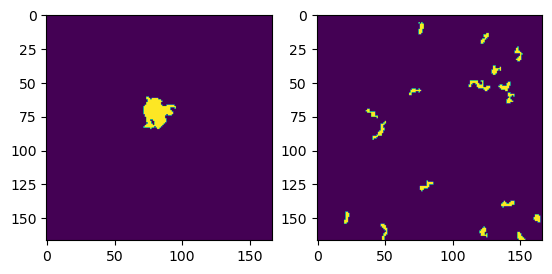

77


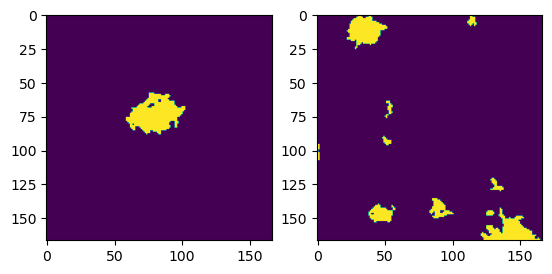

78


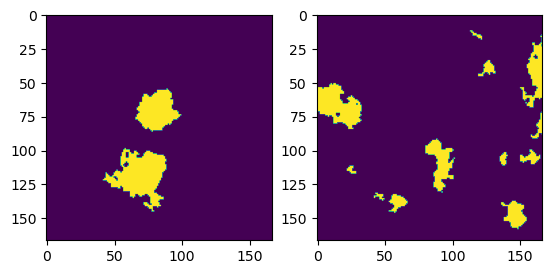

79


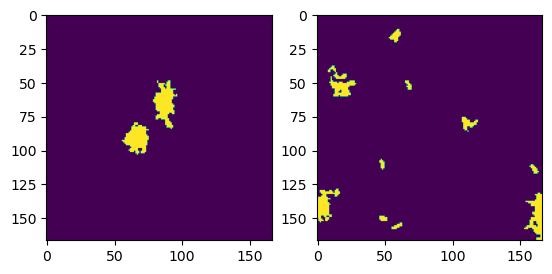

80


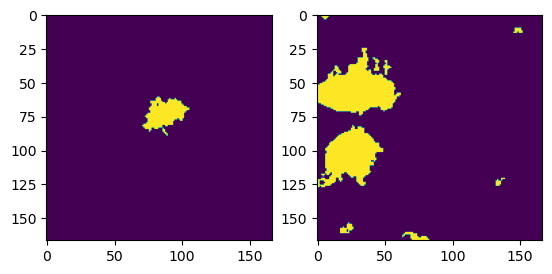

81


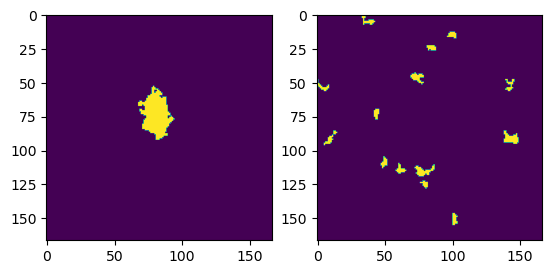

82


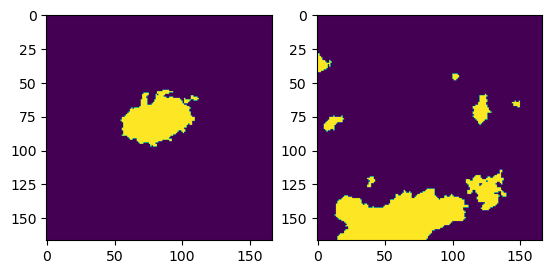

83


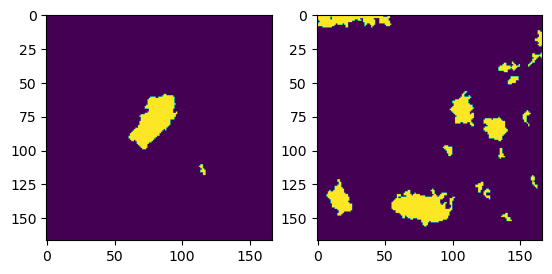

84


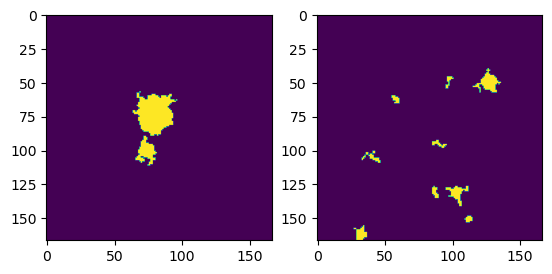

85


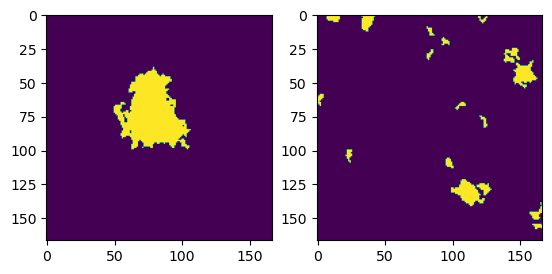

86


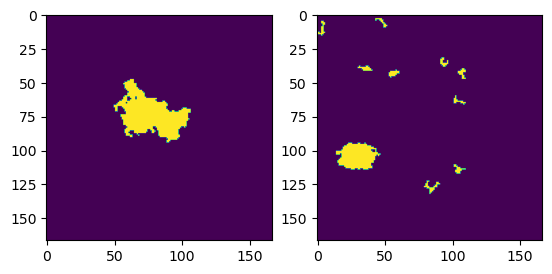

87


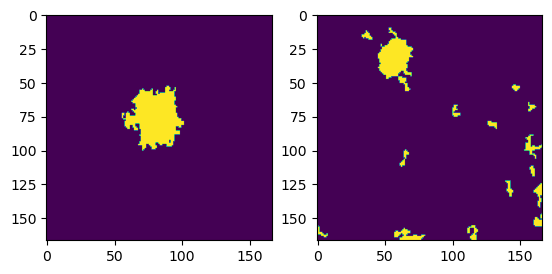

88


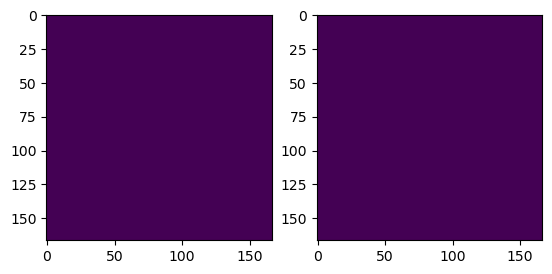

89


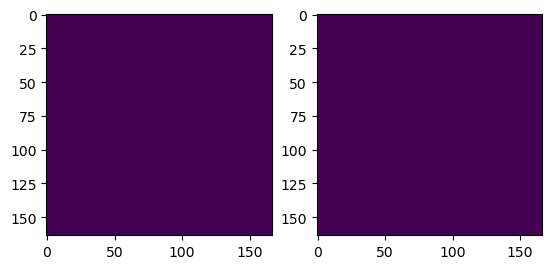

In [583]:
for i in range(len(combine_highz_segment_arr)):
    print(i)
    plt.subplot(121)
    plt.imshow(combine_highz_segment_arr[i])
    plt.subplot(122)
    plt.imshow(bg_segment_arr[i])
    plt.show()

In [584]:
gal_match = Match_Gal()
combine_highz_segment_arr, bg_segment_arr = gal_match.combine_highz_segments_arr(good_indices=good_ind, \
                                                bad_deblended_objectIDs=bad_deblended_objectIDs,\
                                                catalog=c0, catalog_matcher=cat_indx_match,\
                                                objectID_arr=sample_data['id'],\
                                                wcs_arr=cutout_target_image_arr, segments_arr=segment_arr,\
                                                deblended_segments_arr=segm_deblend_arr, z_lim=3.08, use_3sigma_redshift_confidence=False,\
                                                force_segmentation_indices=force_segment_indicies, \
                                                    force_segmentation_values=force_segment_labels)

using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift
using mean photometric redshift


In [585]:
#for i in range(len(cutout_target_image_arr)):
#    # Create a SkyCoord object for the current RA and Dec
#    coord = SkyCoord(ra=sample_data['RA'][i] * u.deg, dec=sample_data['dec'][i] * u.deg, frame='icrs')
#    
#    # Convert the sky coordinates to pixel coordinates using the WCS of the image
#    sky_pix_x, sky_pix_y = cutout_target_image_arr[i].wcs.world_to_pixel(coord)
#    print(i)
#    plt.subplot(141)
#    plt.imshow(np.ma.masked_equal(target_data_bg_sub_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, origin='lower')
#    plt.scatter(sky_pix_x, sky_pix_y, color='red', marker='x', )#label='Coord')
#    plt.legend()
#
#    plt.subplot(142)
#    plt.title('%s' % sample_data['id'][i])
#    plt.imshow(np.ma.masked_equal(secondary_data_bg_sub_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, origin='lower')
#
#    plt.subplot(143)
#    plt.imshow(combine_highz_segment_arr[i], origin='lower')
#
#    plt.subplot(144)
#    plt.imshow(bg_segment_arr[i], origin='lower')
#
#    plt.show()

In [586]:
bg_remove = Background_remove()
target_data_bg_only_arr, \
    target_data_source_only_arr = bg_remove.process_images_with_masks(data_arrays=target_data_bg_sub_arr,\
                                                source_masks=combine_highz_segment_arr,\
                                                background_masks=bg_segment_arr, good_indices=good_ind, filt=False)
    
secondary_data_bg_only_arr, \
    secondary_data_source_only_arr = bg_remove.process_images_with_masks(data_arrays=secondary_data_bg_sub_arr,\
                                                source_masks=combine_highz_segment_arr,\
                                                background_masks=bg_segment_arr, good_indices=good_ind, filt=False)

/usr/lib/python3/dist-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/himanshu/Dropbox/galaxy_evolution/gal_evol/gal_evol/background.py:70: RuntimeWarning: Mean of empty slice
  noise_loc = np.nanmean(masked_image.compressed())


In [587]:
#for i in range(len(cutout_target_image_arr)):
#    
#    plt.subplot(141)
#    plt.imshow(np.ma.masked_equal(target_data_bg_sub_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#    
#    plt.subplot(143)
#    plt.title('%s'%sample_data['id'][i])
#    plt.imshow(np.ma.masked_equal(secondary_data_bg_sub_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#
#    plt.subplot(142)
#    plt.imshow(np.ma.masked_equal(target_data_source_only_arr[i], value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#
#    plt.subplot(144)
#    plt.imshow(np.ma.masked_equal(secondary_data_source_only_arr[i], value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#
#
#    plt.show()

In [588]:
npixels=140
center_cutouts = Center_Cutouts()
final_cutout_target_img_arr, final_cutout_target_bg_arr, final_cutout_secondary_img_arr, final_cutout_secondary_bg_arr, final_cutout_segment_arr = center_cutouts.center_cutout_arr(target_image_arr=target_data_source_only_arr, secondary_image_arr=secondary_data_source_only_arr,\
                                target_bg_image_arr=target_data_bg_only_arr, secondary_bg_image_arr=secondary_data_bg_only_arr, segment_image_arr=combine_highz_segment_arr, wcs_arr=cutout_target_image_arr, npixels=npixels)
#cropped_secondary_cutout_arr = center_cutouts.center_cutout_arr(secondary_data_source_only_arr, secondary_data_bg_only_arr, wcs_arr=cutout_secondary_image_arr, npixels=npixels)

/home/himanshu/Dropbox/galaxy_evolution/gal_evol/gal_evol/image_process.py:177: RuntimeWarning: Mean of empty slice
  mean_target_bg = np.nanmean(cutout_target_bg.data)
/usr/lib/python3/dist-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/himanshu/Dropbox/galaxy_evolution/gal_evol/gal_evol/image_process.py:180: RuntimeWarning: Mean of empty slice
  mean_secondary_bg = np.nanmean(cutout_secondary_bg.data)


In [589]:
#for i in range(len(cutout_target_image_arr)):
#    
#    plt.subplot(131)
#    plt.imshow(np.ma.masked_equal(final_cutout_target_img_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#    
#    plt.subplot(133)
#    plt.title('%s'%sample_data['id'][i])
#    plt.imshow(np.ma.masked_equal(final_cutout_segment_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#
#    plt.subplot(132)
#    plt.imshow(np.ma.masked_equal(final_cutout_secondary_img_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
#
#
#    plt.show()

In [590]:
#final_cutout_target_img_arr = np.array(final_cutout_target_img_arr)
#final_cutout_secondary_img_arr = np.array(final_cutout_secondary_img_arr)
#final_cutout_segment_arr = np.array(final_cutout_segment_arr)
#final_cutout_target_bg_arr = np.array(final_cutout_target_bg_arr)
#final_cutout_secondary_bg_arr = np.array(final_cutout_secondary_bg_arr)
#cutout_target_image_arr = np.array(cutout_target_image_arr)
#cutout_secondary_image_arr = np.array(cutout_secondary_image_arr)

In [591]:
for i in range(len(cutout_target_image_arr)):
    print(cutout_secondary_image_arr[i].shape)

(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)
(167, 167)


In [592]:
cutout_target_image_arr_1 = Center_Cutouts().pad_cutout_to_size(cutout=cutout_target_image_arr[-1], target_shape=cutout_target_image_arr[0].data.shape)
cutout_target_image_arr[-1] = cutout_target_image_arr_1

cutout_secondary_image_arr_1 = Center_Cutouts().pad_cutout_to_size(cutout=cutout_secondary_image_arr[-1], target_shape=cutout_secondary_image_arr[0].data.shape)
cutout_secondary_image_arr[-1] = cutout_secondary_image_arr_1

In [593]:
for i in range(54, 58):#len(cutout_target_image_arr)):
    # Create a SkyCoord object for the current RA and Dec
    coord = SkyCoord(ra=sample_data['RA'][i] * u.deg, dec=sample_data['dec'][i] * u.deg, frame='icrs')
    
    # Convert the sky coordinates to pixel coordinates using the WCS of the image
    sky_pix_x, sky_pix_y = cutout_target_image_arr[i].wcs.world_to_pixel(coord)
    print(i)
    plt.subplot(141)
    plt.imshow(np.ma.masked_equal(final_cutout_target_img_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, origin='lower')
    plt.scatter(sky_pix_x, sky_pix_y, color='red', marker='x', )#label='Coord')
    plt.legend()

    plt.subplot(142)
    plt.title('%s' % sample_data['id'][i])
    plt.imshow(np.ma.masked_equal(final_cutout_secondary_img_arr[i].data, value=0.0), vmin=-0.1, vmax=0.1, origin='lower')

    plt.subplot(143)
    plt.imshow(final_cutout_segment_arr[i].data, origin='lower')

    plt.subplot(144)
    plt.imshow(final_cutout_target_bg_arr[i].data, origin='lower')

    plt.show()

ValueError: no field of name RA

In [594]:
saving_data = Save_Data(target_image_arr=final_cutout_target_img_arr, secondary_image_arr=final_cutout_secondary_img_arr, target_segment_arr=final_cutout_segment_arr, target_bg_arr=final_cutout_target_bg_arr,\
    secondary_bg_arr=final_cutout_secondary_bg_arr, target_original_arr=cutout_target_image_arr,\
    secondary_original_arr=cutout_secondary_image_arr, sample_data=sample_data, )
saving_data.save_fits(sample_type='EELGs', target_filter_name=filt0, secondary_filter_name=filt1, savepath=data_path+'spec_data/EELGs/', skip_target=True)

FITS file EELGs_final_filters_f444w.fits created successfully.


In [261]:
fits_read = fits.open(data_path+ "EELGs_final_filters_f444w_f090w.fits")

In [262]:
fits_read.info()

Filename: /media/himanshu/MyHDD/data_galaxy_evolution/data/EELGs_final_filters_f444w_f090w.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  f444w:original-image    1 PrimaryHDU       8   (167, 167, 27)   float32   
  1  f090w:original-image    1 ImageHDU         9   (167, 167, 27)   float32   
  2  segmentation-masks    1 ImageHDU         9   (140, 140, 27)   uint8   
  3  f444w-cutouts    1 ImageHDU         9   (140, 140, 27)   float64   
  4  f090w-cutouts    1 ImageHDU         9   (140, 140, 27)   float64   
  5  f444w-background    1 ImageHDU         9   (140, 140, 27)   float64   
  6  f090w-background    1 ImageHDU         9   (140, 140, 27)   float64   
  7  WCS           1 ImageHDU        36   (1, 1)   float64   
  8  WCS           1 ImageHDU        36   (1, 1)   float64   
  9  WCS           1 ImageHDU        36   (1, 1)   float64   
 10  WCS           1 ImageHDU        36   (1, 1)   float64   
 11  WCS           1 ImageHDU        36   (1, 1)   float64  

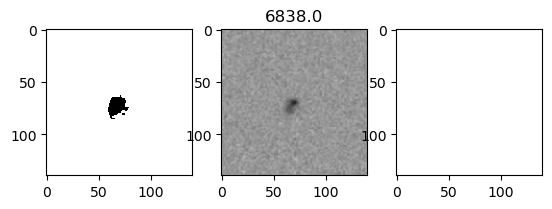

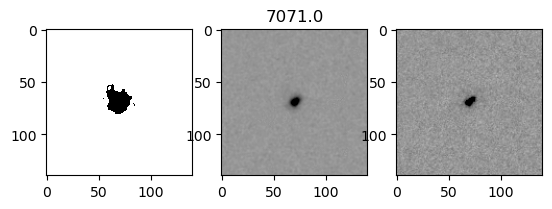

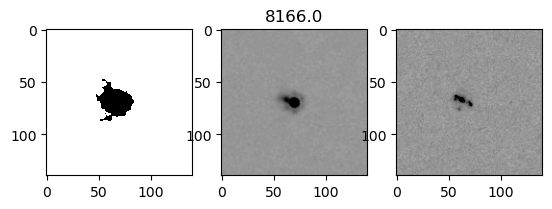

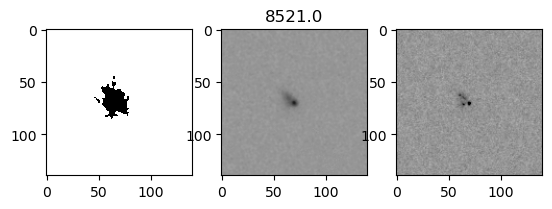

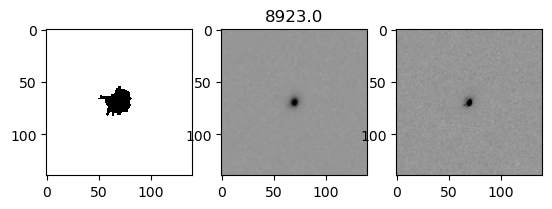

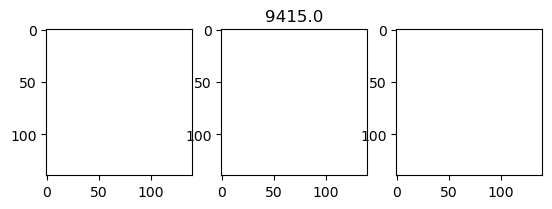

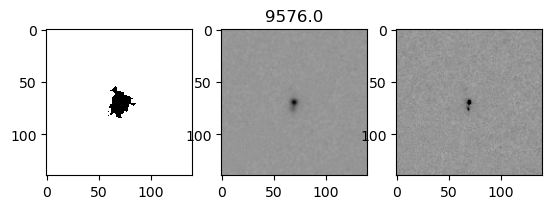

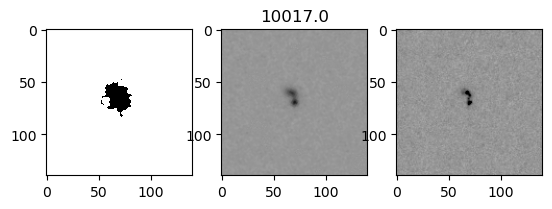

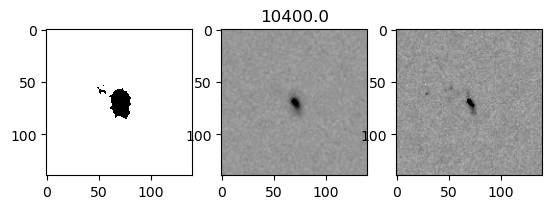

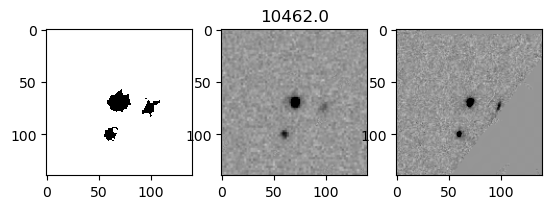

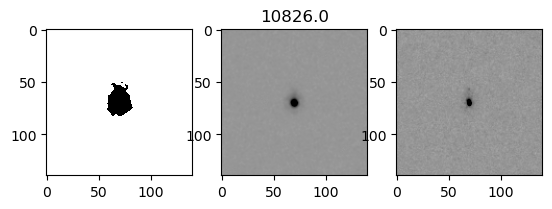

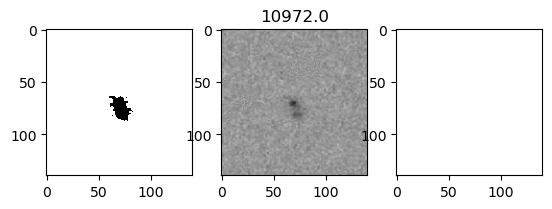

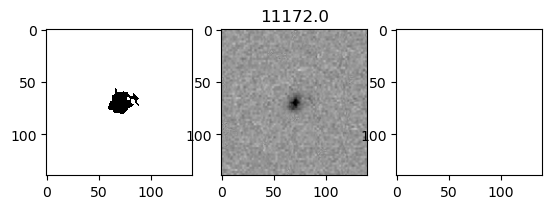

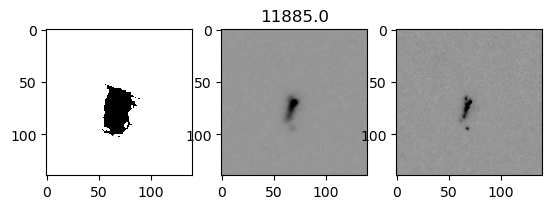

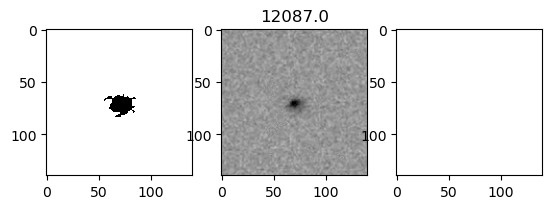

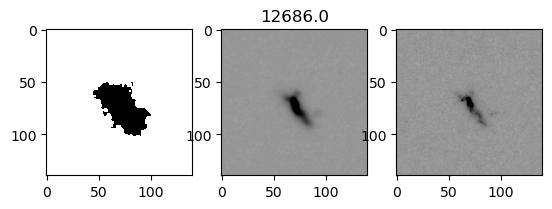

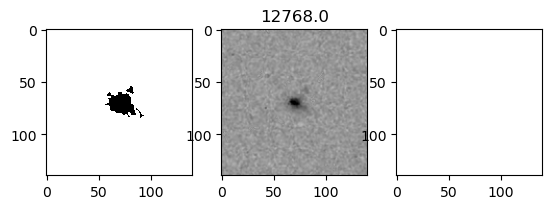

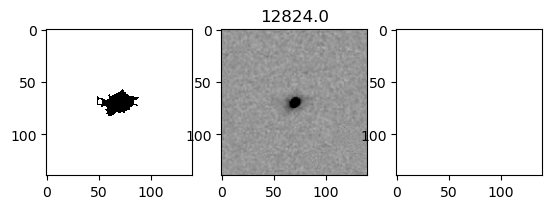

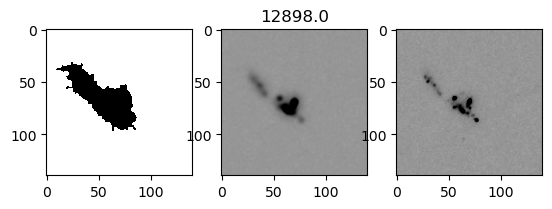

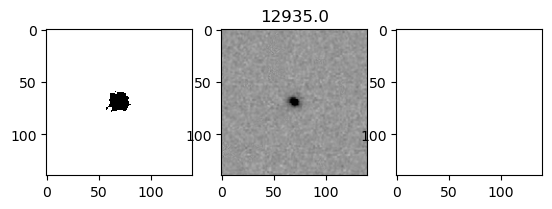

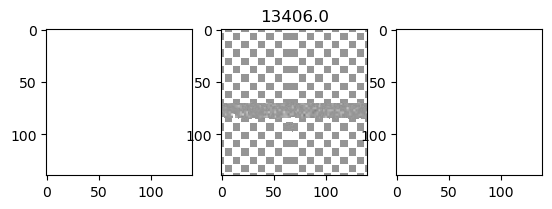

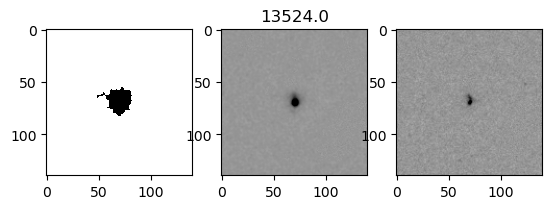

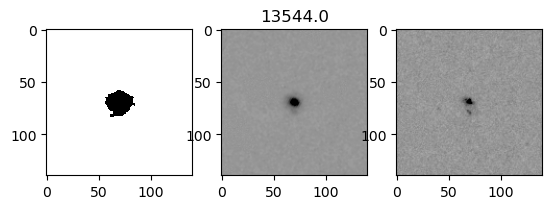

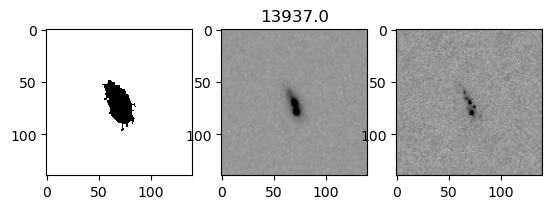

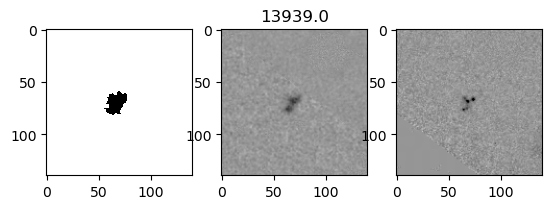

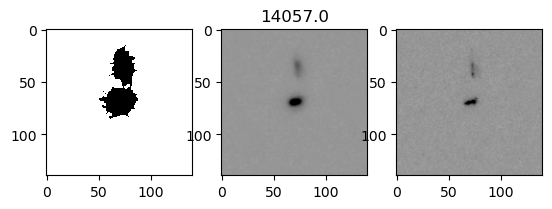

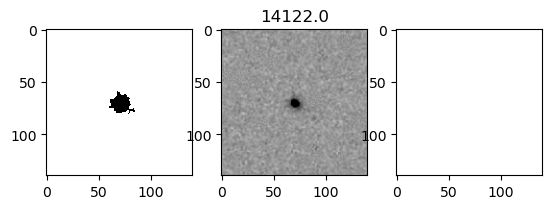

In [263]:
for i in range(len(fits_read[4].data)):
    
    plt.subplot(131)
    plt.imshow(np.ma.masked_equal(fits_read[2].data[i], value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')
    
    plt.subplot(132)
    plt.title('%s'%sample_data['id'][i])
    plt.imshow(np.ma.masked_equal(fits_read[3].data[i], value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')

    plt.subplot(133)
    plt.imshow(np.ma.masked_equal(fits_read[4].data[i], value=0.0), vmin=-0.1, vmax=0.1, cmap='Greys')


    plt.show()

/tmp/ipykernel_669860/2844319453.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.2, h_pad=0.1, w_pad=0.1)


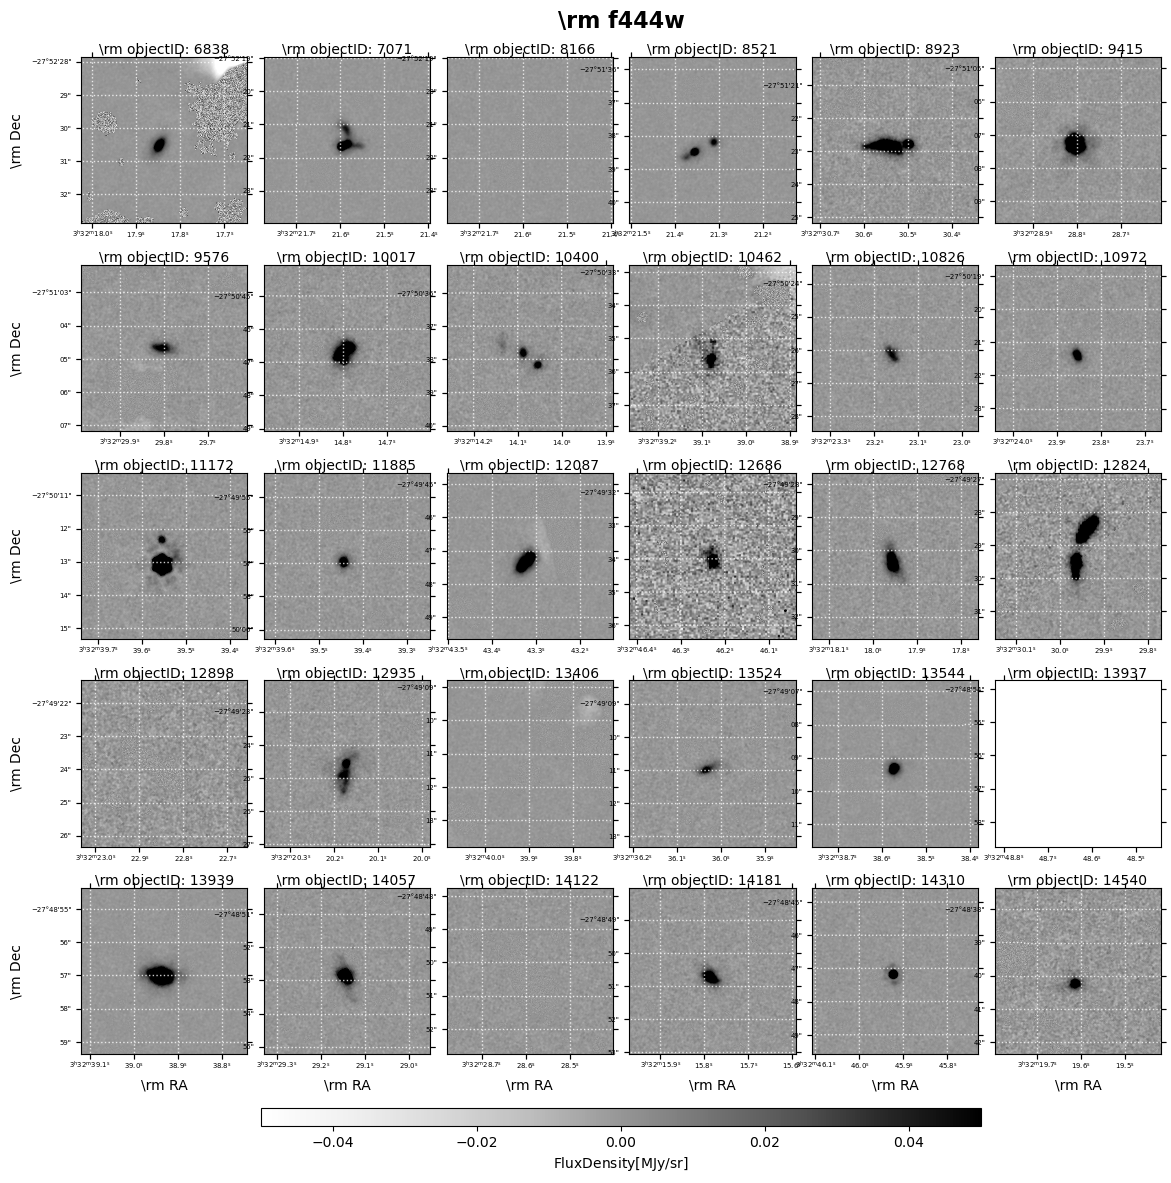

In [264]:
# Define the number of rows and columns for the grid
rows, cols = 5, 6

# Create the figure and GridSpec for better spacing control
fig = plt.figure(figsize=(12, 12))
gs = GridSpec(rows, cols, figure=fig, hspace=0.1, wspace=0.1)

# Adjusted suptitle position to be closer to the figure
fig.suptitle(r'\rm %s' % filt0, fontsize=16, fontweight='bold', y=0.95)

# Store axes for later modifications
axes = []

# Plot each image on the grid
for i in range(rows * cols):
    if i < len(target_data_bg_only_arr):
        # Get the WCS for the current image
        current_wcs = cutout_target_image_arr[i].wcs

        # Create a subplot with the current WCS
        ax = fig.add_subplot(gs[i], projection=current_wcs)
        axes.append(ax)  # Store for reference

        # Mask zero values and plot the image
        data = np.ma.masked_equal(target_data_source_only_arr[i].data, 0)
        im = ax.imshow(data, origin='lower', cmap='Greys', vmin=-0.05, vmax=0.05)
        ax.set_title(r"\rm objectID: %d" % sample_data['id'][i], fontsize=10, pad=2)

        # Overlay RA/Dec grid with dotted lines
        ax.coords.grid(color='white', linestyle='dotted', lw=1., alpha=0.8)

        # Ensure tick labels (RA, Dec values) remain visible
        ax.coords[0].set_ticklabel(size=5)
        ax.coords[1].set_ticklabel(size=5)

        # Only show RA label on the last row
        if i >= (rows - 1) * cols:
            ax.coords[0].set_axislabel(r'\rm RA', fontsize=10)
        else:
            ax.coords[0].set_axislabel('')

        # Only show Dec label on the leftmost column
        if i % cols == 0:
            ax.coords[1].set_axislabel(r'\rm Dec', fontsize=10)
        else:
            ax.coords[1].set_axislabel('')
    else:
        # If no more images, create an empty subplot
        ax = fig.add_subplot(gs[i])
        ax.axis('off')  # Hide unused slots

# Add a big horizontal colorbar at the bottom
cbar_ax = fig.add_axes([0.2, 0.02, 0.6, 0.015])  # Adjusted lower for better fit
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r'$\rm Flux Density [%s]$' % flux_units, fontsize=10)
cbar.ax.tick_params(labelsize=10)

# Adjust layout to minimize space between images
plt.tight_layout(pad=0.2, h_pad=0.1, w_pad=0.1)
plt.subplots_adjust(left=0.05, right=0.95, top=0.92, bottom=0.07)  # Fine-tuned figure spacing


# Show the plot
plt.show()


In [265]:
def dayOfProgrammer(year):
    # Write your code here
    arr = [31, 28, 31, 30 , 31, 30, 31, 31, 30, 31, 30, 31]
    days=0
    if year <= 1917:
        if (year% 4 == 0):
            arr[1] = arr[1]+1
        for i in range(len(arr)):
            days+= arr[i]
            if days > 256:
                date = ['%s'%((256+arr[i])-days), '{:02d}'.format(i+1), '%s'%year]
                break
          
    elif year == 1918:
        arr[1] = arr[1]-14
        for i in range(len(arr)):
            days+= arr[i]
            if days > 256:
                date = ['%s'%((256+arr[i])-days), '{:02d}'.format(i+1), '%s'%year] 
                break
    
    else:
        if (year% 400 == 0) or (year%4==0 and year%100!=0):
            arr[1] = arr[1]+1
        for i in range(len(arr)):
            print(arr[i])
            days+= arr[i]
            if days > 256:
                date = ['%s'%((256+arr[i])-days), '{:02d}'.format(i+1), '%s'%year]
                break
    print('.'.join(date)) 

In [266]:
dayOfProgrammer(year=2016)

31
29
31
30
31
30
31
31
30
12.09.2016


In [ ]:
274-256